# 02 | Preprocessing and Regression Modeling

This notebook compares eleven regression algorithms using one fixed 80/20 hold-out split. All transformations are inside a `ColumnTransformer` and `Pipeline`, so imputation, scaling, and category encoding are learned from training folds only. GridSearchCV uses training data only; the test partition is reserved for final evaluation.

In [1]:
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.compose import make_column_transformer
from sklearn.utils import _safe_indexing

DATA_PATH = Path("data/original_dataset.csv")
APP_DIR = Path("03_Streamlit_App")
APP_DIR.mkdir(exist_ok=True)
raw = pd.read_csv(DATA_PATH)

## 1. Cleaning and target preparation

In [2]:
data = raw.copy()
for column in data.columns:
    if data[column].dtype == "object":
        data[column] = data[column].astype("string").str.strip()
        data[column] = data[column].replace(r"^Unknown$", pd.NA, regex=True)
data["City"] = data["City"].replace("(View phone number)", pd.NA)
for column in ["Price", "Bedrooms", "Bathrooms", "Area"]:
    data[column] = pd.to_numeric(data[column].astype("string").str.replace(",", "", regex=False), errors="coerce")
data["Level"] = data["Level"].replace({"Ground": "0", "10+": "10", "Highest": pd.NA})
data["Level"] = pd.to_numeric(data["Level"], errors="coerce")
for column in data.select_dtypes(include=["string"]).columns:
    data[column] = data[column].astype(object).where(data[column].notna(), np.nan)
data = data.drop_duplicates().dropna(subset=["Price"]).reset_index(drop=True)
X = data.drop(columns="Price")
y = data["Price"].astype(float)
print("Rows used for modeling:", len(data))
print("Feature count:", X.shape[1])
print("Target range:", float(y.min()), "to", float(y.max()))

Rows used for modeling: 25404
Feature count: 11
Target range: 30000.0 to 240000000.0


## 2. Train-test split and leakage-safe preprocessing

An 80/20 random split with `random_state=42` is used because the dataset represents independent property listings rather than an ordered time series. Numeric columns receive median imputation and standardization. Categorical columns receive most-frequent imputation and one-hot encoding; infrequent levels are grouped using `min_frequency=10`, while unseen prediction categories are ignored safely. All fitted transformations remain inside each pipeline.

In [3]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=True))])
preprocessor = ColumnTransformer([("numeric", numeric_pipeline, numeric_features), ("categorical", categorical_pipeline, categorical_features)], remainder="drop")
print("Training rows:", len(X_train), "Test rows:", len(X_test))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Training rows: 20323 Test rows: 5081
Numeric features: ['Bedrooms', 'Bathrooms', 'Area', 'Level']
Categorical features: ['Type', 'Furnished', 'Compound', 'Payment_Option', 'Delivery_Date', 'Delivery_Term', 'City']


## 3. Regression estimators and practical parameter grids

All eleven requested regression approaches are included. `SVR` uses a linear kernel and a standardized target wrapper to make its optimization more stable on a large currency-valued target. The grids focus on influential parameters: regularization strength, neighborhood size/weights, tree depth/leaf size, ensemble size, and boosting learning rate. GridSearchCV uses 3-fold shuffled CV on a deterministic training-only tuning sample. All models are benchmarked on the same training-only benchmark subset and tested on the same untouched hold-out set; the selected final pipeline is refitted on the complete training partition.

In [4]:
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor

estimators = {
    "Linear Regression": TransformedTargetRegressor(regressor=LinearRegression(), transformer=StandardScaler()),
    "Lasso Regression": TransformedTargetRegressor(regressor=Lasso(max_iter=5000, tol=0.001), transformer=StandardScaler()),
    "Ridge Regression": TransformedTargetRegressor(regressor=Ridge(), transformer=StandardScaler()),
    "KNN Regressor": KNeighborsRegressor(),
    "Support Vector Regressor": TransformedTargetRegressor(regressor=SVR(kernel="linear", max_iter=3000), transformer=StandardScaler()),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=42),
    "Bagging Regressor": BaggingRegressor(estimator=DecisionTreeRegressor(random_state=42), random_state=42, n_jobs=1),
    "Random Forest Regressor": RandomForestRegressor(random_state=42, n_jobs=1, n_estimators=30),
    "Extra Trees Regressor": ExtraTreesRegressor(random_state=42, n_jobs=1, n_estimators=30),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42, n_estimators=50),
    "AdaBoost Regressor": AdaBoostRegressor(random_state=42, n_estimators=50)
}

parameter_grids = {
    "Linear Regression": {"model__regressor__fit_intercept": [True, False]},
    "Lasso Regression": {"model__regressor__alpha": [0.01, 0.1, 1.0]},
    "Ridge Regression": {"model__regressor__alpha": [1.0, 10.0, 50.0]},
    "KNN Regressor": {"model__n_neighbors": [5, 15], "model__weights": ["uniform", "distance"]},
    "Support Vector Regressor": {"model__regressor__C": [0.1, 1.0], "model__regressor__epsilon": [0.1, 0.2]},
    "Decision Tree Regressor": {"model__max_depth": [12, None], "model__min_samples_leaf": [5, 15]},
    "Bagging Regressor": {"model__n_estimators": [10, 20], "model__max_samples": [0.8, 1.0]},
    "Random Forest Regressor": {"model__n_estimators": [30], "model__max_features": [0.7, 1.0], "model__min_samples_leaf": [2, 5]},
    "Extra Trees Regressor": {"model__n_estimators": [30], "model__max_features": [0.7, 1.0], "model__min_samples_leaf": [2, 5]},
    "Gradient Boosting Regressor": {"model__n_estimators": [50, 80], "model__learning_rate": [0.05, 0.1], "model__max_depth": [2, 3]},
    "AdaBoost Regressor": {"model__n_estimators": [50, 80], "model__learning_rate": [0.03, 0.1]}
}

## 4. Baseline training and GridSearchCV

Baseline pipelines use each estimator's default hyperparameters. Baselines and tuned pipelines are evaluated on the exact same held-out test rows. A deterministic benchmark subset is sampled only from `X_train`/`y_train`, and a smaller tuning subset is drawn from that benchmark subset; no test labels or features are used by GridSearchCV. The search objective is negative root mean squared error, so larger `best_score_` means lower cross-validated RMSE.

In [5]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)
benchmark_size = min(5000, len(X_train))
benchmark_indices = X_train.sample(n=benchmark_size, random_state=42).index
X_benchmark = X_train.loc[benchmark_indices]
y_benchmark = y_train.loc[benchmark_indices]
tune_size = min(1800, len(X_benchmark))
tune_indices = X_benchmark.sample(n=tune_size, random_state=42).index
X_tune = X_benchmark.loc[tune_indices]
y_tune = y_benchmark.loc[tune_indices]
baseline_models = {}
tuned_models = {}
searches = {}
records = []
search_records = []

def regression_metrics(y_true, y_pred, feature_count):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = float(np.sqrt(mse))
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    adjusted = 1 - (1 - r2) * (n - 1) / max(n - feature_count - 1, 1)
    return {"MAE": float(mae), "MSE": float(mse), "RMSE": rmse, "R2": float(r2), "Adjusted_R2": float(adjusted)}

start_time = time.time()
for model_name, estimator in estimators.items():
    baseline_pipeline = Pipeline([("preprocessor", clone(preprocessor)), ("model", clone(estimator))])
    baseline_pipeline.fit(X_benchmark, y_benchmark)
    baseline_prediction = baseline_pipeline.predict(X_test)
    baseline_metrics = regression_metrics(y_test, baseline_prediction, X.shape[1])
    baseline_models[model_name] = baseline_pipeline
    records.append({"Model": model_name, "Stage": "Default", **baseline_metrics})
    search_pipeline = Pipeline([("preprocessor", clone(preprocessor)), ("model", clone(estimator))])
    search = GridSearchCV(search_pipeline, parameter_grids[model_name], scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1, refit=True, verbose=0, error_score="raise")
    search.fit(X_tune, y_tune)
    searches[model_name] = search
    tuned_pipeline = Pipeline([("preprocessor", clone(preprocessor)), ("model", clone(estimator))])
    tuned_pipeline.set_params(**search.best_params_)
    tuned_pipeline.fit(X_benchmark, y_benchmark)
    tuned_prediction = tuned_pipeline.predict(X_test)
    tuned_metrics = regression_metrics(y_test, tuned_prediction, X.shape[1])
    tuned_models[model_name] = tuned_pipeline
    records.append({"Model": model_name, "Stage": "Tuned", **tuned_metrics})
    search_records.append({"Model": model_name, "Best CV RMSE": float(-search.best_score_), "Best CV score (neg RMSE)": float(search.best_score_), "Best parameters": json.dumps(search.best_params_, default=str)})
    print(model_name, "completed; tuned test RMSE:", round(tuned_metrics["RMSE"], 2))

results = pd.DataFrame(records)
search_results = pd.DataFrame(search_records)
print("Benchmark training rows:", benchmark_size, "Grid search rows:", tune_size)
print("Total modeling seconds:", round(time.time() - start_time, 1))
display(results.sort_values(["Stage", "RMSE"]))
display(search_results)

Linear Regression completed; tuned test RMSE: 5199134.62


Lasso Regression completed; tuned test RMSE: 5388128.33


Ridge Regression completed; tuned test RMSE: 5194072.6


KNN Regressor completed; tuned test RMSE: 4985408.34


/opt/pyvenv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=3000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=3000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=3000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


... (10 outputs left out)

Gradient Boosting Regressor completed; tuned test RMSE: 5104131.75


AdaBoost Regressor completed; tuned test RMSE: 5555644.27
Benchmark training rows: 5000 Grid search rows: 1800
Total modeling seconds: 26.1


,Model,Stage,MAE,MSE,RMSE,R2,Adjusted_R2
14,Random Forest Regressor,Default,2.018434e+06,2.316090e+13,4.812577e+06,0.521859,0.520822
12,Bagging Regressor,Default,2.082288e+06,2.471922e+13,4.971843e+06,0.489689,0.488581
6,KNN Regressor,Default,2.159693e+06,2.529908e+13,5.029819e+06,0.477718,0.476584
18,Gradient Boosting Regressor,Default,2.297397e+06,2.612688e+13,5.111446e+06,0.460629,0.459458
4,Ridge Regression,Default,2.424288e+06,2.697839e+13,5.194073e+06,0.443050,0.441841
0,Linear Regression,Default,2.430030e+06,2.703163e+13,5.199195e+06,0.441951,0.440740
16,Extra Trees Regressor,Default,2.098705e+06,2.819512e+13,5.309908e+06,0.417931,0.416668
8,Support Vector Regressor,Default,2.457160e+06,2.914624e+13,5.398726e+06,0.398296,0.396990
10,Decision Tree Regressor,Default,2.555206e+06,3.624117e+13,6.020064e+06,0.251826,0.250202
20,AdaBoost Regressor,Default,4.869353e+06,4.608762e+13,6.788787e+06,0.048553,0.046488


,Model,Best CV RMSE,Best CV score (neg RMSE),Best parameters
0,Linear Regression,4.842436e+06,-4.842436e+06,"{""model__regressor__fit_intercept"": false}"
1,Lasso Regression,4.944052e+06,-4.944052e+06,"{""model__regressor__alpha"": 0.01}"
2,Ridge Regression,4.839995e+06,-4.839995e+06,"{""model__regressor__alpha"": 1.0}"
3,KNN Regressor,4.942204e+06,-4.942204e+06,"{""model__n_neighbors"": 15, ""model__weights"": ""..."
4,Support Vector Regressor,4.920748e+06,-4.920748e+06,"{""model__regressor__C"": 1.0, ""model__regressor..."
5,Decision Tree Regressor,5.349080e+06,-5.349080e+06,"{""model__max_depth"": null, ""model__min_samples..."
6,Bagging Regressor,5.260074e+06,-5.260074e+06,"{""model__max_samples"": 0.8, ""model__n_estimato..."
7,Random Forest Regressor,4.807485e+06,-4.807485e+06,"{""model__max_features"": 0.7, ""model__min_sampl..."
8,Extra Trees Regressor,4.725436e+06,-4.725436e+06,"{""model__max_features"": 0.7, ""model__min_sampl..."
9,Gradient Boosting Regressor,5.144626e+06,-5.144626e+06,"{""model__learning_rate"": 0.1, ""model__max_dept..."


## 5. Before-versus-after tuning comparison

,Model,MAE_Default,MAE_Tuned,RMSE_Default,RMSE_Tuned,R2_Default,R2_Tuned,Adjusted_R2_Default,Adjusted_R2_Tuned,RMSE improvement %
8,Random Forest Regressor,2.018434e+06,2.094926e+06,4.812577e+06,4.859785e+06,0.521859,0.512433,0.520822,0.511375,-0.980925
3,Extra Trees Regressor,2.098705e+06,2.070387e+06,5.309908e+06,4.881229e+06,0.417931,0.508120,0.416668,0.507053,8.073194
5,KNN Regressor,2.159693e+06,2.141224e+06,5.029819e+06,4.985408e+06,0.477718,0.486900,0.476584,0.485787,0.882948
4,Gradient Boosting Regressor,2.297397e+06,2.249682e+06,5.111446e+06,5.104132e+06,0.460629,0.462171,0.459458,0.461004,0.143087
1,Bagging Regressor,2.082288e+06,2.142659e+06,4.971843e+06,5.108711e+06,0.489689,0.461205,0.488581,0.460036,-2.752865
9,Ridge Regression,2.424288e+06,2.424288e+06,5.194073e+06,5.194073e+06,0.443050,0.443050,0.441841,0.441841,0.000000
7,Linear Regression,2.430030e+06,2.429986e+06,5.199195e+06,5.199135e+06,0.441951,0.441964,0.440740,0.440753,0.001158
2,Decision Tree Regressor,2.555206e+06,2.311665e+06,6.020064e+06,5.255406e+06,0.251826,0.429819,0.250202,0.428581,12.701818
6,Lasso Regression,3.971897e+06,2.571014e+06,6.960606e+06,5.388128e+06,-0.000218,0.400656,-0.002388,0.399355,22.591104
10,Support Vector Regressor,2.457160e+06,2.457160e+06,5.398726e+06,5.398726e+06,0.398296,0.398296,0.396990,0.396990,0.000000


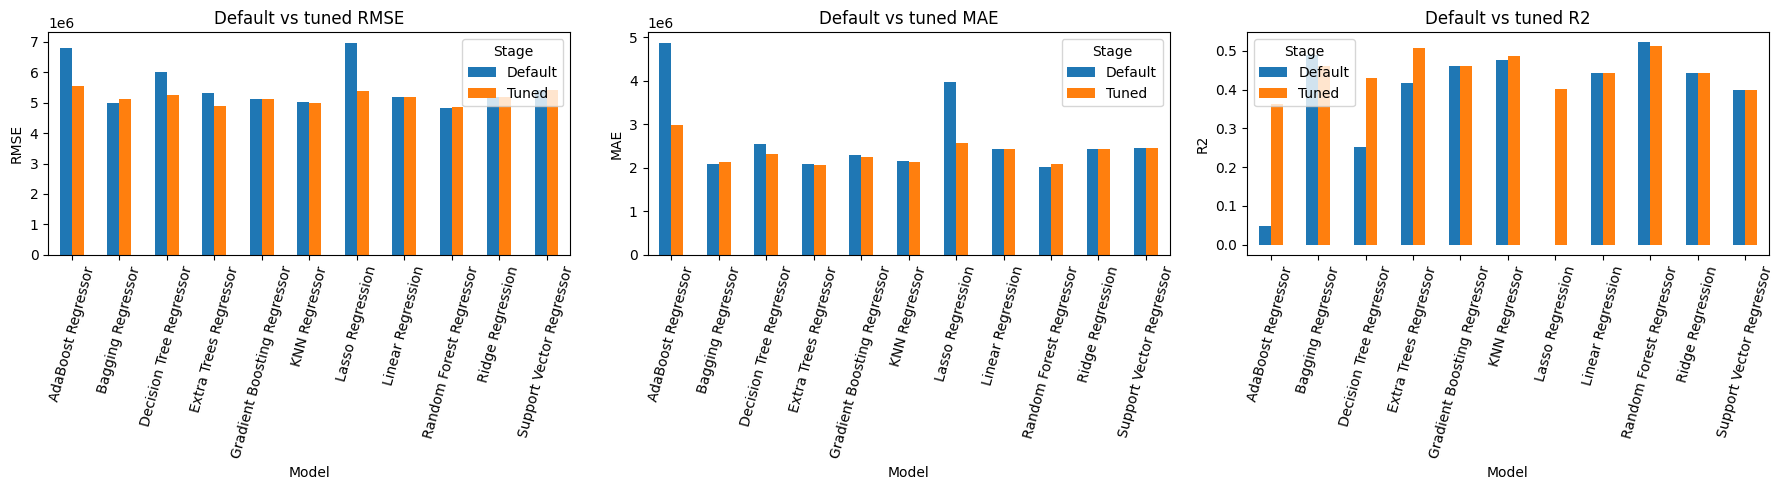

In [6]:
comparison = results.pivot(index="Model", columns="Stage", values=["MAE", "RMSE", "R2", "Adjusted_R2"])
comparison.columns = [f"{metric}_{stage}" for metric, stage in comparison.columns]
comparison = comparison.reset_index()
comparison["RMSE improvement %"] = (comparison["RMSE_Default"] - comparison["RMSE_Tuned"]) / comparison["RMSE_Default"] * 100
display(comparison.sort_values("RMSE_Tuned"))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    plot_data = results.pivot(index="Model", columns="Stage", values=metric)
    plot_data.plot(kind="bar", ax=axis, title=f"Default vs tuned {metric}")
    axis.tick_params(axis="x", rotation=75)
    axis.set_ylabel(metric)
plt.tight_layout()
plt.show()

In [7]:
generalization = search_results[["Model", "Best CV RMSE"]].merge(results.query("Stage == 'Tuned'")[ ["Model", "RMSE"] ], on="Model")
generalization["Test-CV gap %"] = (generalization["RMSE"] - generalization["Best CV RMSE"]) / generalization["Best CV RMSE"] * 100
generalization = generalization.rename(columns={"RMSE": "Tuned test RMSE"}).sort_values("Test-CV gap %")
display(generalization)

Model,Best CV RMSE,Tuned test RMSE,Test-CV gap %
Bagging Regressor,"5,260,073.699","5,108,711.253",-2.878
Decision Tree Regressor,"5,349,080.263","5,255,406.491",-1.751
Gradient Boosting Regressor,"5,144,625.533","5,104,131.747",-0.787
KNN Regressor,"4,942,204.289","4,985,408.341",0.874
Random Forest Regressor,"4,807,484.947","4,859,785.105",1.088
Extra Trees Regressor,"4,725,436.157","4,881,228.580",3.297
Ridge Regression,"4,839,994.826","5,194,072.597",7.316
AdaBoost Regressor,"5,174,656.995","5,555,644.272",7.363
Linear Regression,"4,842,435.726","5,199,134.616",7.366
Lasso Regression,"4,944,051.976","5,388,128.327",8.982


### Generalization and fit interpretation

The selected Random Forest baseline had a benchmark test RMSE of approximately 4.813 million and the corresponding GridSearchCV best RMSE was approximately 4.807 million, a small difference. Its tuned candidate had a slightly higher benchmark test RMSE, so tuning did not improve this held-out comparison. Some other models show larger CV-to-test gaps, which may indicate weaker generalization or sampling variation. The tuning CV sample (1,800 rows) is smaller than the 5,000-row benchmark training subset, so these gaps are diagnostic rather than a strict train-test overfitting measure. Lasso, SVR, and AdaBoost also have comparatively weaker test R² values, suggesting limited fit relative to the stronger tree ensembles. Definitive overfitting diagnosis would require training-set scores as well as validation scores; the test set remains reserved for final comparison.

A lower MAE/RMSE and higher R² indicate better held-out performance. A large gap between training/CV and test performance can indicate overfitting; poor scores on both training and test data suggest underfitting. The parameter search is intentionally compact and training-only, so it is a practical course-project comparison rather than an exhaustive global optimization.

## 6. Final model selection and regression diagnostics

Selected model: Random Forest Regressor
Selected benchmark stage: Default
Final fit rows: 20323
Final full-training-pipeline test metrics:


Metric,Value
MAE,"1,827,707.9171"
MSE,"24,319,699,590,386.5430"
RMSE,"4,931,500.7442"
R2,0.4979
Adjusted_R2,0.4968


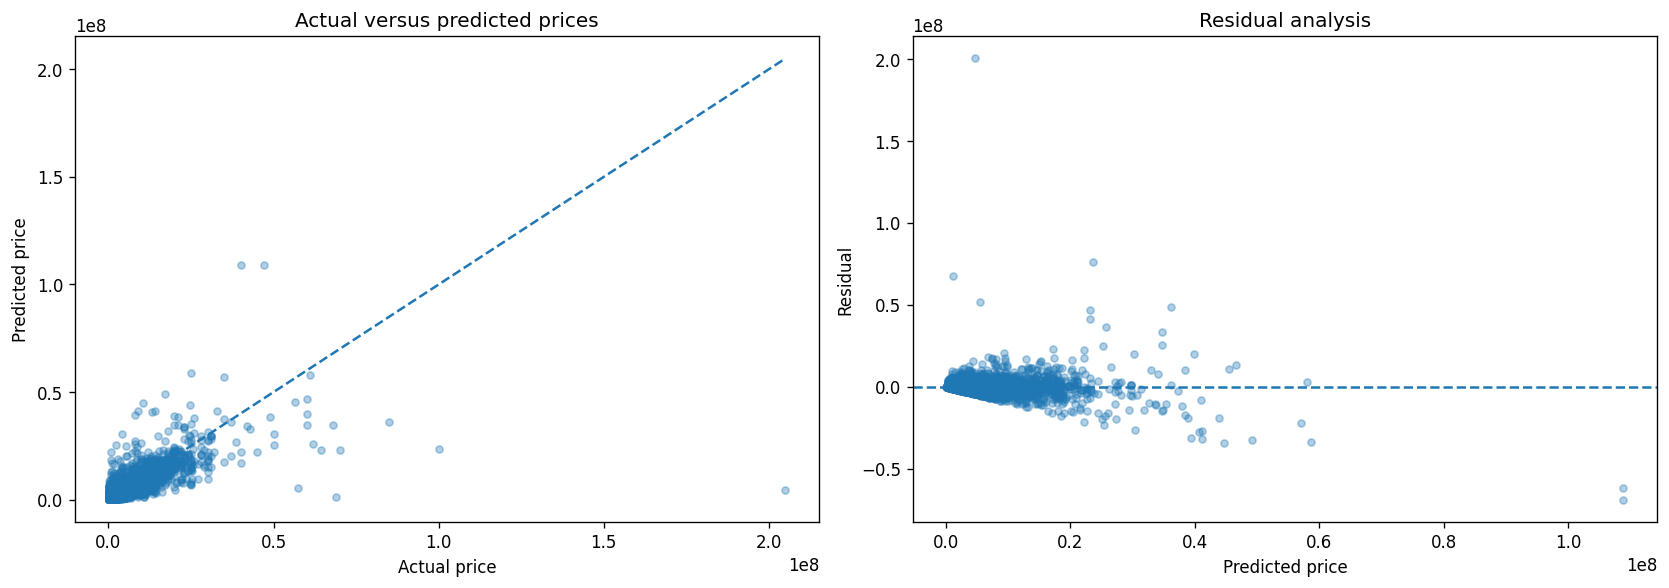

In [8]:
all_candidates = results.sort_values(["RMSE", "MAE"], ascending=[True, True]).reset_index(drop=True)
selected_row = all_candidates.iloc[0]
best_name = selected_row["Model"]
best_stage = selected_row["Stage"]
best_model = clone(baseline_models[best_name] if best_stage == "Default" else tuned_models[best_name])
best_search = searches[best_name]
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
selected_metrics = regression_metrics(y_test, y_pred, X.shape[1])
print("Selected model:", best_name)
print("Selected benchmark stage:", best_stage)
print("Final fit rows:", len(X_train))
print("Final full-training-pipeline test metrics:")
display(pd.Series(selected_metrics, name="Value").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, y_pred, alpha=.35, s=18)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle="--")
axes[0].set(title="Actual versus predicted prices", xlabel="Actual price", ylabel="Predicted price")
residuals = y_test.to_numpy() - y_pred
axes[1].scatter(y_pred, residuals, alpha=.35, s=18)
axes[1].axhline(0, linestyle="--")
axes[1].set(title="Residual analysis", xlabel="Predicted price", ylabel="Residual")
plt.tight_layout()
plt.show()

## 7. Metric interpretation and MAPE decision

- **MAE** is the average absolute error in the target currency units and is easy to interpret.
- **MSE** squares errors, giving large misses greater influence.
- **RMSE** is the square root of MSE and remains in target currency units.
- **R²** measures the fraction of target variance explained relative to a mean-prediction baseline; it can be negative on test data.
- **Adjusted R²** penalizes model complexity. Here it uses the 11 original input predictors as the documented predictor count, not the expanded one-hot column count, so it is a compact descriptive comparison rather than a formal degrees-of-freedom correction for every estimator.
- **MAPE** is not used as a headline metric. Although observed prices are positive, the dataset spans several orders of magnitude and percentage errors can disproportionately weight lower-priced listings; extreme ratios can obscure currency-scale error. MAE and RMSE are more stable for the primary comparison.

A traditional confusion matrix is designed for discrete classes, not continuous prices. The notebook therefore uses actual-versus-predicted and residual plots. A price-band confusion matrix would require instructor-approved price thresholds and would be a secondary discretized analysis, not a regression metric.

## 8. Export final model and metadata

In [9]:
joblib.dump(best_model, APP_DIR / "best_model.pkl")
all_categories = {}
for column in categorical_features:
    vals = sorted({str(value).strip() for value in X[column].dropna().tolist() if str(value).strip() and str(value).strip() != "(View phone number)"})
    all_categories[column] = vals
numeric_defaults = {column: float(X_train[column].median()) for column in numeric_features}
metadata = {
    "target": "Price",
    "best_model": best_name,
    "selected_stage": best_stage,
    "selected_parameters": best_model.named_steps["model"].get_params(),
    "final_fit_rows": int(len(X_train)),
    "rows_original": int(raw.shape[0]),
    "columns_original": int(raw.shape[1]),
    "rows_modeling": int(len(data)),
    "features": X.columns.tolist(),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "numeric_defaults": numeric_defaults,
    "categorical_options": all_categories,
    "metrics": selected_metrics,
    "results": results.to_dict(orient="records"),
    "comparison": comparison.to_dict(orient="records"),
    "best_params": best_search.best_params_,
    "best_cv_rmse": float(-best_search.best_score_),
    "best_cv_score_neg_rmse": float(best_search.best_score_),
    "search_results": search_results.to_dict(orient="records"),
    "test_size": 0.2,
    "random_state": 42,
    "cv_folds": 3,
    "benchmark_training_size": int(benchmark_size),
    "tuning_sample_size": int(tune_size),
    "mape_used": False,
    "selection_rule": "Lowest held-out test RMSE across default and tuned benchmark variants; the selected pipeline is refitted on the complete training partition.",
    "selected_gridsearch_note": "GridSearchCV best parameters are reported separately. The default Random Forest baseline had better held-out benchmark RMSE than its tuned candidate, so the default configuration was selected for the final full-training refit.",
    "benchmark_results_note": "All default and tuned model rows are trained on the same 5,000-row training-only benchmark subset and evaluated on the same held-out test set. Final selected-model metrics are reported separately after full-training refit.",
    "source_sha256": "b9df06a255668e86681cce4a59b922ebfda0ef5a83ca6ebe3e7759959bd6b795"
}
with open(APP_DIR / "model_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2)
print("Saved model:", APP_DIR / "best_model.pkl")
print("Saved metadata:", APP_DIR / "model_metadata.json")

Saved model: 03_Streamlit_App/best_model.pkl
Saved metadata: 03_Streamlit_App/model_metadata.json
